# 06. Recurso adicional (critério 10): monitoramento de drift sazonal com alerta

**Problema identificado.** O vigente pode ficar muitos ciclos sem ser trocado, e ninguém olha os notebooks todo dia. Precisamos ser avisados quando os dados saem do normal (um mês muito mais quente ou seco que o habitual, ou uma mudança na própria fonte) e quando o modelo começa a errar mais. A checagem de drift mais comum compara os dados recentes com o treino inteiro. Em clima isso dispara alerta quase todo mês, porque novembro sempre é diferente da média do ano. Alarme que toca sempre vira ruído e passa a ser ignorado.

**Solução.** Comparar com a mesma época do ano.
1. **Drift dos dados:** PSI (Population Stability Index) de cada feature do vigente nos últimos 30 dias contra os dias da mesma época (com 15 dias de margem) nos anos de treino do vigente. Calculamos também contra o ano todo, só para mostrar a diferença. As features de calendário (`dia_ano_*`) ficam de fora, porque são só a data.
2. **Drift do desempenho:** MAE do vigente nos últimos 30 dias contra o MAE dele nas mesmas datas do ano anterior. Essas datas estão na validação, que o vigente nunca viu no treino.
3. **Alerta:** se alguma feature passar do `limiar_psi` ou se o erro passar de 1,5 vez o do ano anterior. O alerta vai para o MLflow e para as evidências do ciclo, e no GitHub Actions abre (ou comenta) a issue "Alerta de drift" no repositório.

**Calibração.** Com só 30 dias o PSI tem um piso de ruído, então o limiar clássico de 0,25 dispararia demais. Rodamos a mesma checagem em todos os meses antigos do treino (backtest) e fixamos o limiar no `config.yaml` para disparar pouco em meses normais.

**Ponto de integração.** É o último notebook do workflow, depois das previsões. O passo seguinte do YAML lê o `alerta.md` gerado aqui e abre a issue.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
from src import ciclo, modelagem, monitoramento, preprocessamento, promocao

cfg = ciclo.carregar_config()
estado = ciclo.atual()
mlflow = ciclo.configurar_mlflow(cfg)
dataset, janelas = preprocessamento.carregar(cfg)
pd.set_option("display.precision", 3)
print(f"ciclo {estado['cycle_id']} | {estado['data_version']}")
import matplotlib.pyplot as plt

ciclo 20261107-205440 | dv-20261024-622a2671


In [2]:
mon = cfg["monitoramento"]
manifesto = promocao.ler_manifesto()
modelo = mlflow.sklearn.load_model(manifesto["model_uri"])
monitoradas = [f for f in manifesto["features"] if not f.startswith("dia_ano")]
referencia = dataset.loc[: manifesto["treino_ate"]]
recente = dataset.tail(mon["janela_dias"])
print(f"janela recente: {recente.index.min():%d/%m/%Y} a {recente.index.max():%d/%m/%Y}; "
      f"referência: treino do vigente até {manifesto['treino_ate']}")

psis = monitoramento.comparar(referencia, recente, monitoradas, mon)
psis.sort_values("psi_sazonal", ascending=False)

janela recente: 25/09/2026 a 24/10/2026; referência: treino do vigente até 2025-09-23


,psi_anual,psi_sazonal
tmax,0.267,0.246
radiacao,0.214,0.239
rajada,0.059,0.197
vento_dir_cos,0.299,0.165
tmed,0.746,0.091
pressao_delta,0.047,0.064
tmin,0.939,0.046


## Backtest: quantas vezes cada referência teria disparado

191 janelas de 30 dias no treino do vigente. Com limiar 1.0, o alerta teria disparado em 72% delas com a referência do ano todo e em 3% com a sazonal.


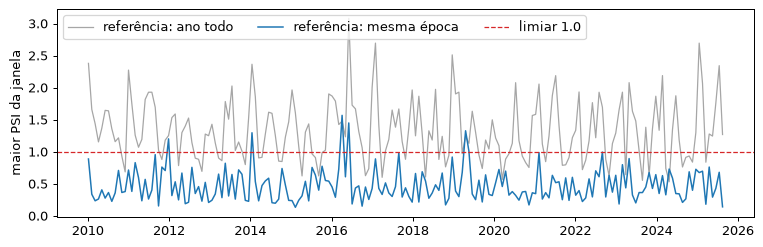

In [3]:
bt = monitoramento.backtest(referencia, monitoradas, mon)
taxa = (bt > mon["limiar_psi"]).mean()
print(f"{len(bt)} janelas de {mon['janela_dias']} dias no treino do vigente. Com limiar {mon['limiar_psi']}, o alerta "
      f"teria disparado em {taxa.psi_anual:.0%} delas com a referência do ano todo e em {taxa.psi_sazonal:.0%} com a sazonal.")

fig, ax = plt.subplots(figsize=(10, 3), dpi=90)
ax.plot(bt.index, bt.psi_anual, color="0.65", lw=1, label="referência: ano todo")
ax.plot(bt.index, bt.psi_sazonal, color="tab:blue", lw=1.2, label="referência: mesma época")
ax.axhline(mon["limiar_psi"], color="tab:red", ls="--", lw=1, label=f"limiar {mon['limiar_psi']}")
ax.set_ylabel("maior PSI da janela")
ax.legend(loc="upper left", ncols=3)
plt.show()

## Desempenho recente contra o mesmo período do ano anterior

In [4]:
teste = janelas["teste"]
ano_antes = dataset.reindex(teste.index - pd.Timedelta(days=365)).dropna(subset=["alvo"])
feats = manifesto["features"]
mae_recente = modelagem.metricas(teste.alvo, modelo.predict(teste[feats]))["mae"]
mae_ano_antes = modelagem.metricas(ano_antes.alvo, modelo.predict(ano_antes[feats]))["mae"]
razao = mae_recente / mae_ano_antes
print(f"MAE últimos {len(teste)} dias: {mae_recente:.3f} | mesmas datas do ano anterior: {mae_ano_antes:.3f} | razão {razao:.2f}")

MAE últimos 30 dias: 2.209 | mesmas datas do ano anterior: 1.792 | razão 1.23


## Decisão do alerta

In [5]:
motivos = []
acima = psis.index[psis.psi_sazonal > mon["limiar_psi"]].tolist()
if acima:
    motivos.append(f"drift sazonal em {', '.join(acima)} (PSI máximo {psis.psi_sazonal.max():.2f}, limiar {mon['limiar_psi']})")
if razao > mon["limiar_razao_mae"]:
    motivos.append(f"erro do último mês {razao:.2f} vezes o do mesmo período do ano anterior (limite {mon['limiar_razao_mae']})")
alerta = bool(motivos)
print("ALERTA: " + "; ".join(motivos) if alerta else "sem alerta neste ciclo")

pasta = ciclo.pasta(estado)
psis.to_csv(pasta / "monitoramento.csv", index_label="feature")
if alerta:
    (pasta / "alerta.md").write_text(
        f"Ciclo `{estado['cycle_id']}` (`{estado['data_version']}`), janela de {recente.index.min():%d/%m/%Y} a "
        f"{recente.index.max():%d/%m/%Y}.\n\n" + "\n".join(f"- {m}" for m in motivos)
        + f"\n\nModelo vigente: {manifesto['algoritmo']} do ciclo {manifesto['cycle_id']}.\n", encoding="utf-8")

sem alerta neste ciclo


In [6]:
with mlflow.start_run(run_name=f"{estado['cycle_id']}-monitoramento", tags=ciclo.tags(estado, "monitoramento")) as run:
    mlflow.log_params({"janela_dias": mon["janela_dias"], "margem_sazonal_dias": mon["margem_sazonal_dias"],
                       "bins": mon["bins"], "limiar_psi": mon["limiar_psi"], "limiar_razao_mae": mon["limiar_razao_mae"]})
    mlflow.log_metrics({f"psi_sazonal_{f}": v for f, v in psis.psi_sazonal.items()}
                       | {f"psi_anual_{f}": v for f, v in psis.psi_anual.items()}
                       | {"psi_sazonal_max": psis.psi_sazonal.max(), "psi_anual_max": psis.psi_anual.max(),
                          "razao_mae": razao, "alerta": int(alerta),
                          "backtest_taxa_anual": taxa.psi_anual, "backtest_taxa_sazonal": taxa.psi_sazonal})
    mlflow.log_artifact(pasta / "monitoramento.csv")

estado["monitoramento"] = {"run_id": run.info.run_id, "alerta": alerta, "motivos": motivos,
                           "psi_sazonal_max": psis.psi_sazonal.max(), "psi_anual_max": psis.psi_anual.max(),
                           "razao_mae": razao, "backtest_taxa_anual": taxa.psi_anual,
                           "backtest_taxa_sazonal": taxa.psi_sazonal}
estado["fim_utc"] = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")
ciclo.salvar(estado)
(pasta / "resumo.md").write_text(ciclo.resumo_md(estado), encoding="utf-8")
print(ciclo.resumo_md(estado))

## Ciclo 20261107-205440 (workflow_dispatch)
- data_version: `dv-20261024-622a2671`, 6141 dia(s) novo(s), dados até 2026-10-24
- features eleitas (8): tmed, dia_ano_cos, tmin, radiacao, vento_dir_cos, tmax, pressao_delta, rajada

| modelo | algoritmo | MAE validação |
|---|---|---|
| A | ridge | 1.929 |
| B | hist_gradient_boosting | 1.887 |
| persistência | amanhã = hoje | 2.569 |

- vencedor: **B**; decisão: **promovido** (primeiro ciclo: ainda não havia modelo vigente)
- MAE do vigente no teste (últimos 30 dias): 2.209 °C (persistência: 2.977 °C)
- previsão para 2026-10-25: **25.2 °C**
- monitoramento: sem alerta

